# Weather prediction - time series
- Climate dataset from [Max Planck Institute](https://www.bgc-jena.mpg.de/wetter/)
- Baseline from [keras](https://keras.io/examples/timeseries/timeseries_weather_forecasting/)
- [Open in Colab](https://colab.research.google.com/drive/15jaSG9xdD02dSPKs74LuQ-zmc68pV6-I)

## Setup

Install TFTS and the notebook dependencies into the kernel environment before running all cells:

```python
%pip install tfts matplotlib
```

Use a TFTS release matching these docs. To test the current checkout, install it with `pip install -e .` first. This notebook imports the installed package and does not require repository-only helpers.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from tfts import AutoConfig, AutoModelForForecasting, KerasTrainer

## EDA

In [2]:
from zipfile import ZipFile

uri = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip"
zip_path = tf.keras.utils.get_file(origin=uri, fname="jena_climate_2009_2016.csv.zip")
zip_file = ZipFile(zip_path)
zip_file.extractall()
csv_path = "jena_climate_2009_2016.csv"

df = pd.read_csv(csv_path)
# Keep the default notebook run bounded on laptops/CI. Remove this slice
# to train on the complete Jena Climate dataset.
df = df.iloc[:20000].copy()

df.head()

,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


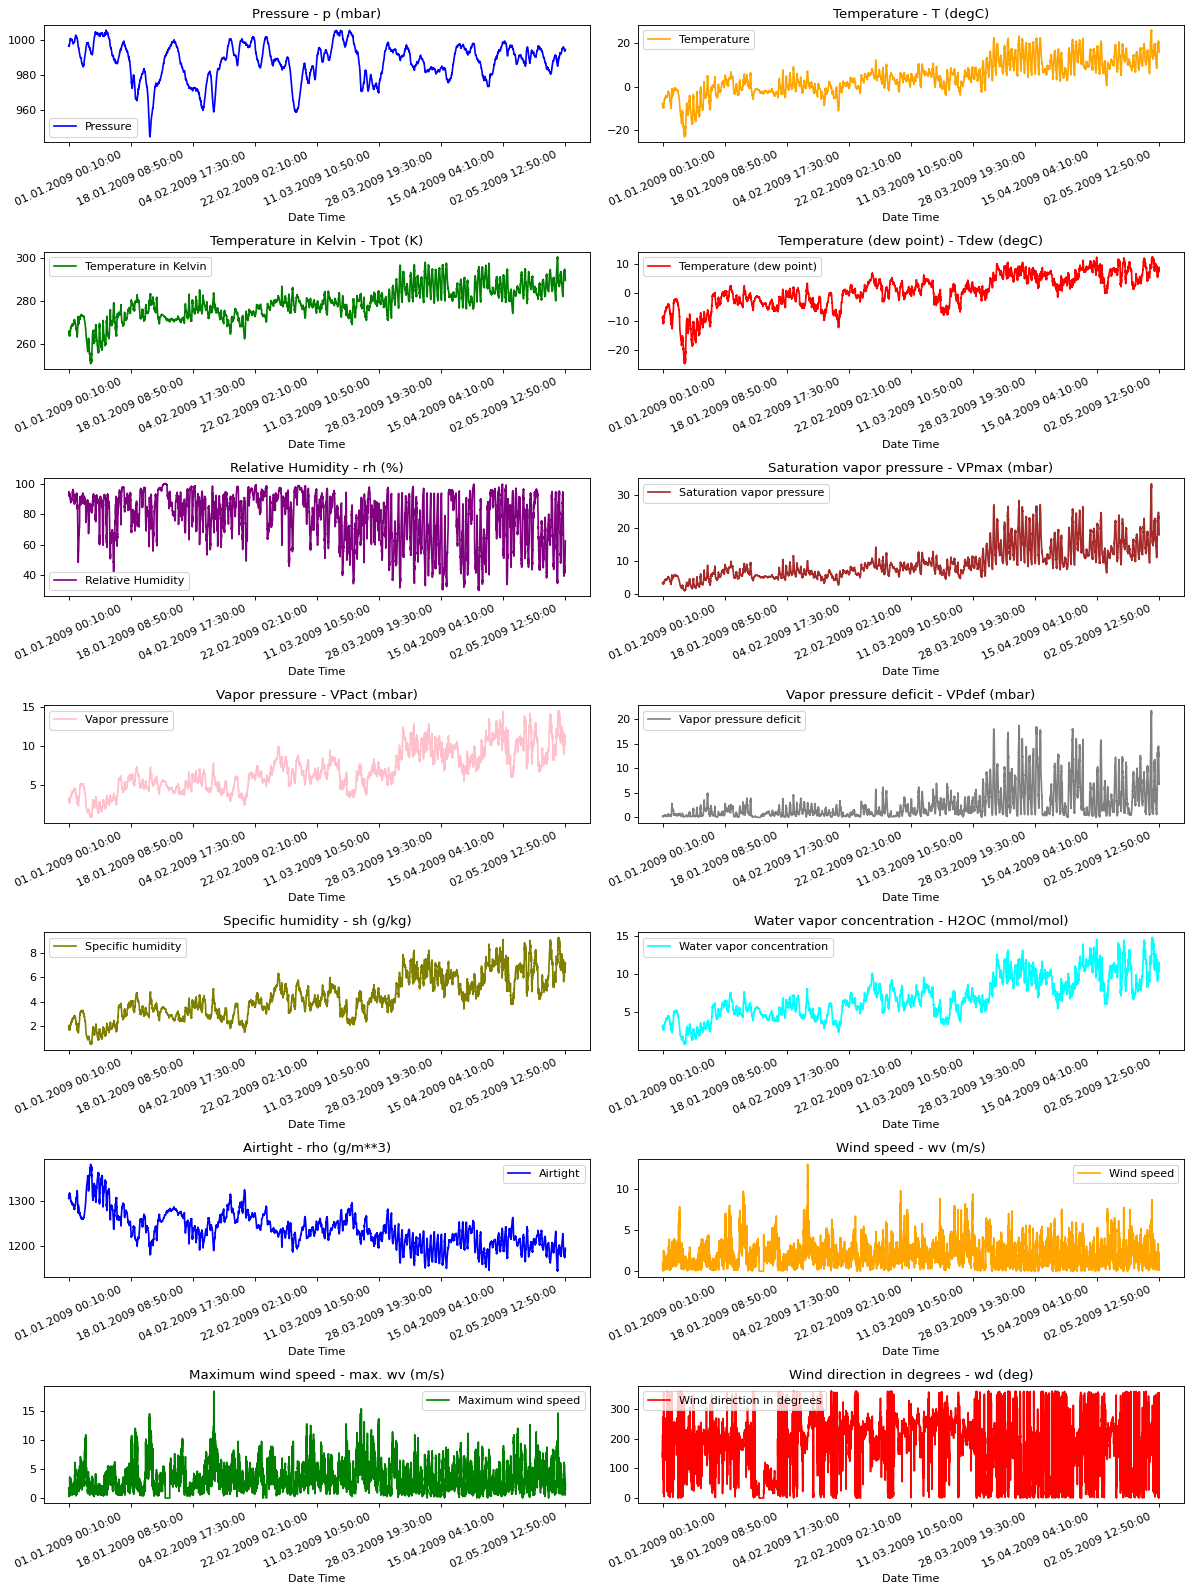

In [3]:
titles = [
    "Pressure",
    "Temperature",
    "Temperature in Kelvin",
    "Temperature (dew point)",
    "Relative Humidity",
    "Saturation vapor pressure",
    "Vapor pressure",
    "Vapor pressure deficit",
    "Specific humidity",
    "Water vapor concentration",
    "Airtight",
    "Wind speed",
    "Maximum wind speed",
    "Wind direction in degrees",
]

feature_keys = [
    "p (mbar)",
    "T (degC)",
    "Tpot (K)",
    "Tdew (degC)",
    "rh (%)",
    "VPmax (mbar)",
    "VPact (mbar)",
    "VPdef (mbar)",
    "sh (g/kg)",
    "H2OC (mmol/mol)",
    "rho (g/m**3)",
    "wv (m/s)",
    "max. wv (m/s)",
    "wd (deg)",
]

colors = [
    "blue",
    "orange",
    "green",
    "red",
    "purple",
    "brown",
    "pink",
    "gray",
    "olive",
    "cyan",
]

date_time_key = "Date Time"


def show_raw_visualization(data):
    time_data = data[date_time_key]
    fig, axes = plt.subplots(nrows=7, ncols=2, figsize=(15, 20), dpi=80, facecolor="w", edgecolor="k")
    for i in range(len(feature_keys)):
        key = feature_keys[i]
        c = colors[i % (len(colors))]
        t_data = data[key]
        t_data.index = time_data
        t_data.head()
        ax = t_data.plot(
            ax=axes[i // 2, i % 2],
            color=c,
            title=f"{titles[i]} - {key}",
            rot=25,
        )
        ax.legend([titles[i]])
    plt.tight_layout()


show_raw_visualization(df)

## Data preparation

In [4]:
split_fraction = 0.8
train_split = int(split_fraction * int(df.shape[0]))
step = 6

past = 720
future = 72
learning_rate = 0.001
batch_size = 64
epochs = 2


def normalize(data, train_split):
    data_mean = data[:train_split].mean(axis=0)
    data_std = data[:train_split].std(axis=0)
    return (data - data_mean) / data_std


print(
    "The selected parameters are:",
    ", ".join([titles[i] for i in [0, 1, 5, 7, 8, 10, 11]]),
)
selected_features = [feature_keys[i] for i in [0, 1, 5, 7, 8, 10, 11]]
features = df[selected_features]
features.index = df[date_time_key]
features.head()

features = normalize(features.values, train_split)
features = pd.DataFrame(features)
features.head()

train_data = features.loc[0 : train_split - 1]
val_data = features.loc[train_split:]

start = past + future
end = train_split  # Keep every training target before the validation cutoff.

x_train = train_data[[i for i in range(7)]].values
y_train = features.iloc[start:end][[1]]

sequence_length = int(past / step)


dataset_train = tf.keras.preprocessing.timeseries_dataset_from_array(
    x_train,
    y_train.to_numpy()[:, None, :],
    sequence_length=sequence_length,
    sampling_rate=step,
    batch_size=batch_size,
)


# valid
x_end = len(val_data) - past - future

label_start = train_split + past + future

x_val = val_data.iloc[:x_end][[i for i in range(7)]].values
y_val = features.iloc[label_start:][[1]]

dataset_val = tf.keras.preprocessing.timeseries_dataset_from_array(
    x_val,
    y_val.to_numpy()[:, None, :],
    sequence_length=sequence_length,
    sampling_rate=step,
    batch_size=batch_size,
)


for batch in dataset_train.take(1):
    inputs, targets = batch

print("Input shape:", inputs.numpy().shape)
print("Target shape:", targets.numpy().shape)

The selected parameters are: Pressure, Temperature, Saturation vapor pressure, Vapor pressure deficit, Specific humidity, Airtight, Wind speed
Input shape: (64, 120, 7)
Target shape: (64, 1, 1)


## Training

In [5]:
model_name_or_path = "rnn"
config = AutoConfig.for_model(model_name_or_path)
config.rnn_type = "lstm"
print(config)

model = AutoModelForForecasting.from_config(config, output_chunk_length=1)

{'hidden_size': 64, 'num_layers': 2, 'num_attention_heads': 4, 'intermediate_size': 256, 'dropout': 0.1, 'layer_norm_eps': 1e-05, 'initializer_range': 0.02, 'target_dim': 1, 'rnn_hidden_size': 64, 'rnn_type': 'lstm', 'bi_direction': False, 'dense_hidden_size': 128, 'num_stacked_layers': 1, 'scheduled_sampling': 0.0, 'use_attention': False, 'return_sequences': False, 'input_projection': False}


In [6]:
%%time
opt = tf.keras.optimizers.Adam(learning_rate)
loss_fn = tf.keras.losses.MeanSquaredError()
trainer = KerasTrainer(model)

early_stop_callback = tf.keras.callbacks.EarlyStopping(monitor="val_loss", min_delta=0, patience=5)

history = trainer.train(
    dataset_train, dataset_val, optimizer=opt, epochs=epochs, batch_size=batch_size, callbacks=[early_stop_callback]
)

Epoch 1/2


/Users/longxingtan/Repository/Time-series-prediction/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  1/238 ━━━━━━━━━━━━━━━━━━━━ 1:19 335ms/step - loss: 7.2068

  2/238 ━━━━━━━━━━━━━━━━━━━━ 51s 217ms/step - loss: 7.9846 

  3/238 ━━━━━━━━━━━━━━━━━━━━ 51s 218ms/step - loss: 5.8338

...

236/238 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step - loss: 0.3834

237/238 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step - loss: 0.3833

238/238 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step - loss: 0.3825

238/238 ━━━━━━━━━━━━━━━━━━━━ 59s 246ms/step - loss: 0.3825 - val_loss: 0.3200


CPU times: user 1min 44s, sys: 16.5 s, total: 2min
Wall time: 1min 57s


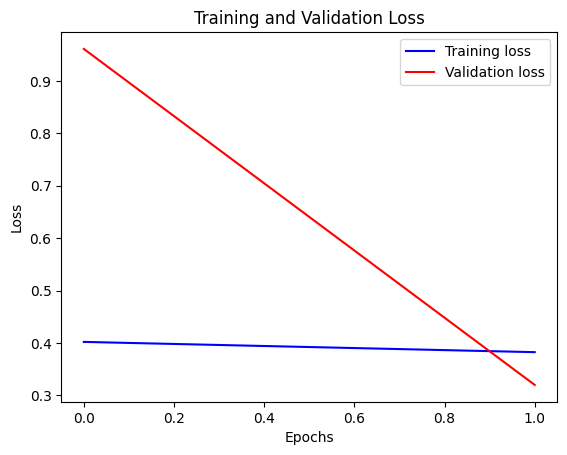

In [7]:
def visualize_loss(history, title):
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]
    epochs = range(len(loss))
    plt.figure()
    plt.plot(epochs, loss, "b", label="Training loss")
    plt.plot(epochs, val_loss, "r", label="Validation loss")
    plt.title(title)
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()


visualize_loss(history, "Training and Validation Loss")

## Evaluation

## Testing

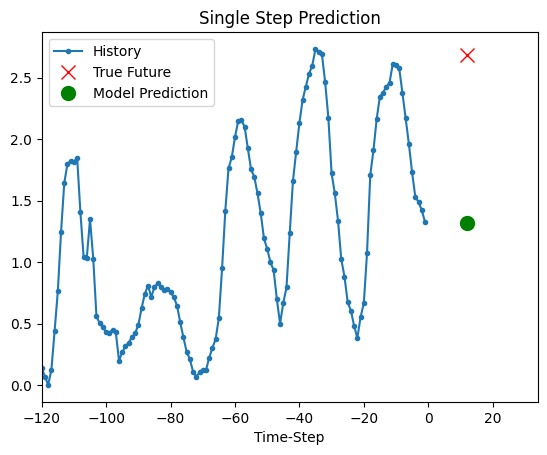

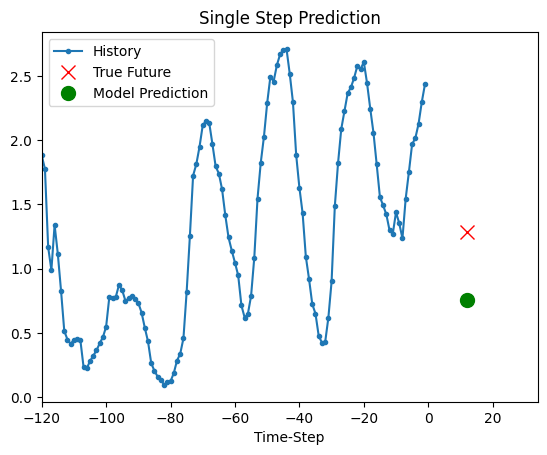

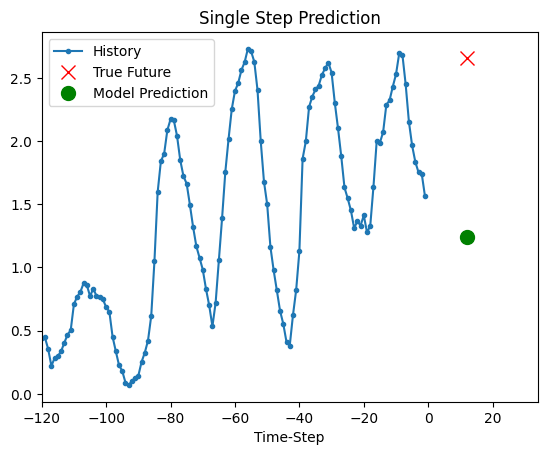

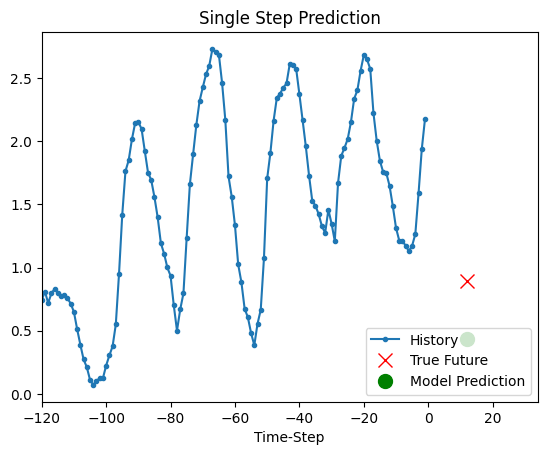

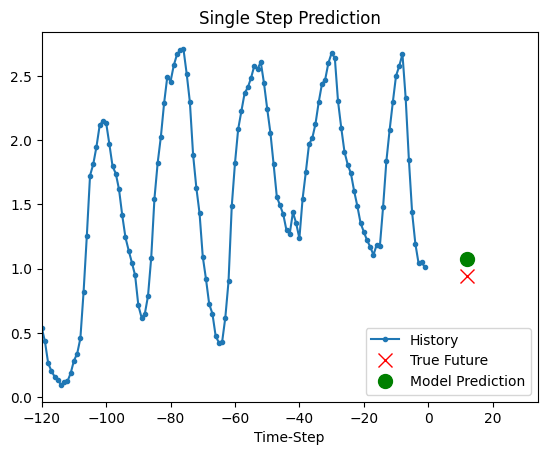

In [8]:
def show_plot(plot_data, delta, title):
    labels = ["History", "True Future", "Model Prediction"]
    marker = [".-", "rx", "go"]
    time_steps = list(range(-(plot_data[0].shape[0]), 0))
    if delta:
        future = delta
    else:
        future = 0

    plt.title(title)
    for i, val in enumerate(plot_data):
        if i:
            plt.plot(future, plot_data[i], marker[i], markersize=10, label=labels[i])
        else:
            plt.plot(time_steps, plot_data[i].flatten(), marker[i], label=labels[i])
    plt.legend()
    plt.xlim([time_steps[0], (future + 5) * 2])
    plt.xlabel("Time-Step")
    plt.show()
    return


for x, y in dataset_val.take(5):
    show_plot(
        [x[0][:, 1].numpy(), y[0, 0].numpy(), model(x).predictions[0, 0]],
        12,
        "Single Step Prediction",
    )

## Save, reload, and run inference

In [9]:
trainer.save_model("./weather_model")
from tfts import AutoModel

inference_x, _ = next(iter(dataset_val.take(1)))
restored_model = AutoModel.from_pretrained("./weather_model", sample_batch=inference_x)
restored_predictions = restored_model(inference_x, training=False).predictions.numpy()
print("Restored prediction shape:", restored_predictions.shape)

Restored prediction shape: (64, 1, 1)
